In [4]:

import numpy as np

#Open files with the TES pressure levels and the retrieved and a prior profiles 
    # for sample 1
f1=open('TES_prof_sample1.dat','r')
        #Read the first line with the lat/lon info and the number of retrieved levels
line = f1.readline().split()
        # Get the number of retrieved levels, which is item 2
num_levs = int(line[1])
        # Read the rest of the file into an array
data1 = np.fromfile(f1,dtype=float,sep=' ')
        # Extract the first num_levs values for the pressure levels
press_lev1 = data1[:num_levs]
        # Extract the second num_levs values for the a priori profile
TES_prior1 = data1[num_levs:(num_levs+num_levs)]   
        # Extract the last num_levs values for the retrieved profile
TES_prof1 = data1[(num_levs+num_levs):]
f1.close()
    # for sample 2
f2=open('TES_prof_sample2.dat','r')
        #Read the first line with the lat/lon info and the number of retrieved levels
line = f2.readline().split()
        # Get the number of retrieved levels, which is item 2
num_levs = int(line[1])
        # Read the rest of the file into an array
data2 = np.fromfile(f2,dtype=float,sep=' ')
        # Extract the first num_levs values for the pressure levels
press_lev2 = data2[:num_levs]
        # Extract the second num_levs values for the a priori profile
TES_prior2 = data2[num_levs:(num_levs+num_levs)]   
        # Extract the last num_levs values for the retrieved profile
TES_prof2 = data2[(num_levs+num_levs):]
f2.close()



# Load the averaging kernel matrices
    # first averaging kernel
f_ak1 = open('TES_avgkern_sample1.dat','r')
data2 = np.fromfile(f_ak1,dtype=float,sep=' ')
TES_akern1 = np.reshape(data2,(num_levs,num_levs))
f_ak1.close()
    # second averaging kernel
f_ak2 = open('TES_avgkern_sample2.dat','r')
data = np.fromfile(f_ak2,dtype=float,sep=' ')
TES_akern2 = np.reshape(data,(num_levs,num_levs))
f_ak2.close()

# Load the covariance matrices
    # first cov matrix
f_cov1 = open('TES_covar_sample1.dat','r')
data3 = np.fromfile(f_cov1,dtype=float,sep=' ')
TES_cov1 = np.reshape(data3,(num_levs,num_levs))
f_cov1.close()
    # second covariance matrix
f_cov2 = open('TES_covar_sample2.dat','r')
data3 = np.fromfile(f_cov2,dtype=float,sep=' ')
TES_cov2 = np.reshape(data3,(num_levs,num_levs))
f_cov2.close()


# load the MOPITT Data
f_mopitt = open('mopitt_xa.dat','r')
	# Read the first line with the lat/lon info and the number of retrieved levels
line = f_mopitt.readline().split()
	# Get the number of retrieved levels, which is item 2
num_levs = int(line[0])
    # Read the rest of the file into an array
datam = np.fromfile(f_mopitt,dtype=float,sep=' ')
	# Extract the first num_levs values for the pressure levels
press_levm = datam[:num_levs]
	# Extract the second num_levs values for the a priori profile
moppit_prior = datam[num_levs:(num_levs+num_levs)]   
f_mopitt.close()


# Q1a

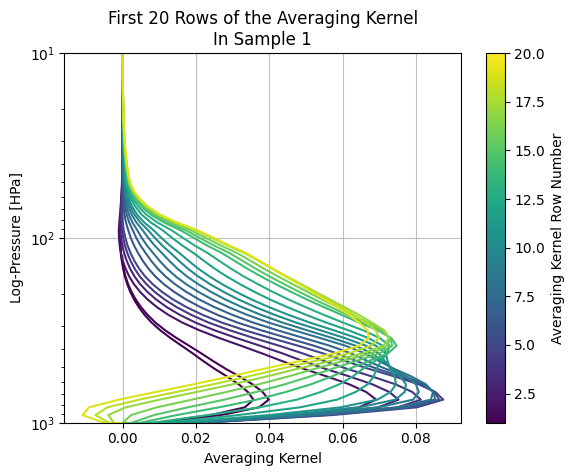

tr(A_1)=1.43675


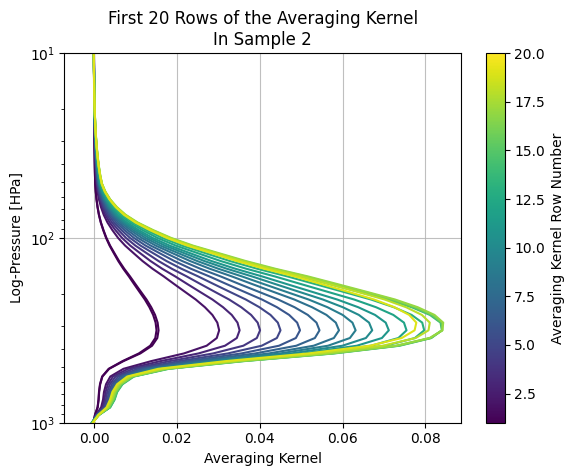

tr(A_2)=0.94078


In [10]:
import matplotlib.pyplot as plt

def make_averaging_kernel_plot(TES_akern, press_lev, sample_num):
    fig, ax = plt.subplots()

    cmap = plt.colormaps['viridis']
    norm = plt.Normalize(vmin=1, vmax=20)

    for i in range(20):
        color = cmap(norm(i))
        ax.plot(TES_akern[i, :], press_lev, color=color)

    # Add colorbar and grid
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax)
    cbar.set_label('Averaging Kernel Row Number')
    plt.grid(alpha=0.8)

    # Make labels and titles
    ax.set_ylabel("Log-Pressure [HPa]")
    ax.set_xlabel("Averaging Kernel")
    ax.set_title(f"First 20 Rows of the Averaging Kernel\nIn Sample {sample_num}")

    # Change scaling of y axis
    ax.set_yscale("log")
    ax.set_ylim(1000, 10)

    # display plot
    plt.savefig(f"../plots/Q1a_{sample_num}.png")
    plt.show()
    plt.close()

    print(f"tr(A_{sample_num})={np.trace(TES_akern):.5f}")

    return


# make plots
make_averaging_kernel_plot(TES_akern1, press_lev1, sample_num=1)
make_averaging_kernel_plot(TES_akern2, press_lev2, sample_num=2)


# Q1b

/nfs/kris/d1/home/groth/humerben/.default_env/lib64/python3.9/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/nfs/kris/d1/home/groth/humerben/.default_env/lib64/python3.9/site-packages/matplotlib/collections.py:197: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


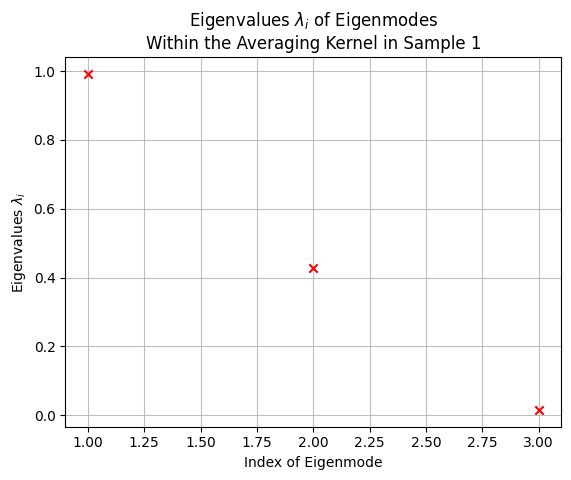

/nfs/kris/d1/home/groth/humerben/.default_env/lib64/python3.9/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


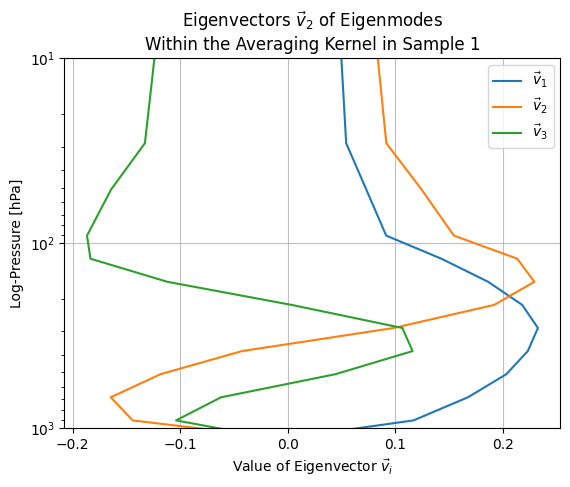

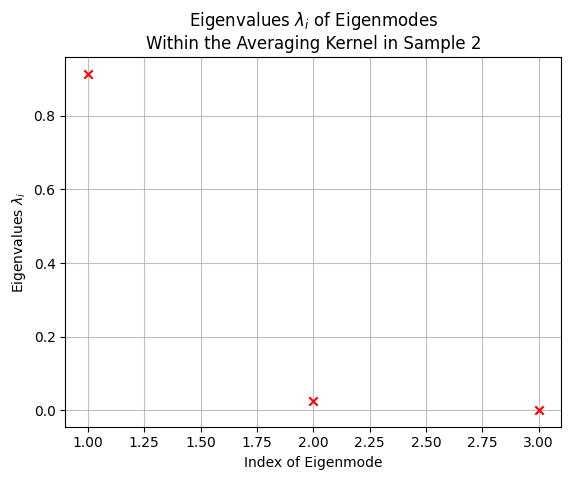

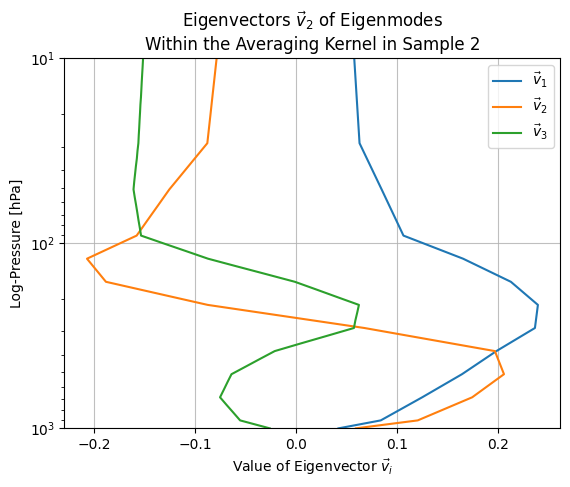

In [6]:
def make_eigenvalue_eigenvector_plot(TES_akern, press_lev, sample_num):
    # calculate how many pieces of information are obtained in the retrievals
    evals, evecs = np.linalg.eig(TES_akern)

    sorting_indices = np.argsort(evals)[::-1]

    sorted_evals = evals[sorting_indices]
    sorted_evecs = evecs[:,sorting_indices]
    eval_indices = np.linspace(1,len(sorted_evals),len(sorted_evals))

    # make plot of eigenvalues to determine influential eigenmodes
    plt.scatter(eval_indices[:3], sorted_evals[:3], color='r', marker='x', zorder=2)
    plt.ylabel(r"Eigenvalues $\lambda_i$")
    plt.xlabel("Index of Eigenmode")
    plt.title(r"Eigenvalues $\lambda_i$ of Eigenmodes"+f"\nWithin the Averaging Kernel in Sample {sample_num}")
    plt.grid(alpha=0.8, zorder=1)
    plt.savefig(f"../plots/Q1b_{sample_num}_evals.png")
    plt.show()
    plt.close()

    # make plot of eigenvectors
    for i in range(3):
        plt.plot(sorted_evecs[:,i], press_lev, label=rf'$\vec{{v}}_{{{i+1}}}$')

    # add in grid and legend
    plt.legend()
    plt.grid(alpha=0.8)

    # add in titles and axis labels
    plt.title(rf"Eigenvectors $\vec{{v}}_{{{i}}}$ of Eigenmodes"+"\n"+rf"Within the Averaging Kernel in Sample {sample_num}")
    plt.ylabel("Log-Pressure [hPa]")
    plt.xlabel(r"Value of Eigenvector $\vec{{v}}_{{i}}$")

    # add scaling to yaxis
    plt.ylim(1000,10)
    plt.yscale("log")

    # show plot and close it
    plt.savefig(f"../plots/Q1b_{sample_num}_evecs.png")
    plt.show()
    plt.close()



    return


make_eigenvalue_eigenvector_plot(TES_akern1, press_lev1, 1)
make_eigenvalue_eigenvector_plot(TES_akern2, press_lev2, 2)

# Q1c

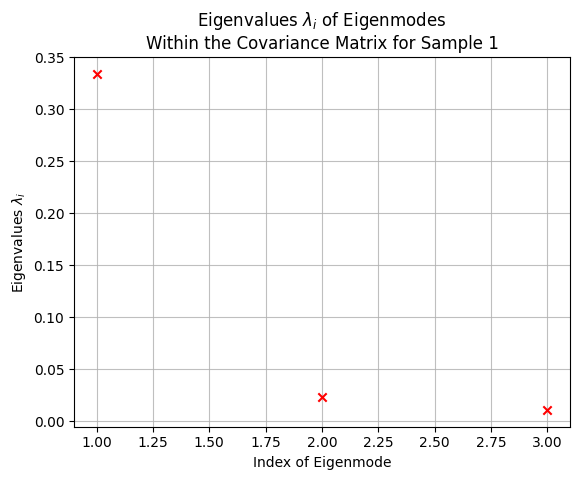

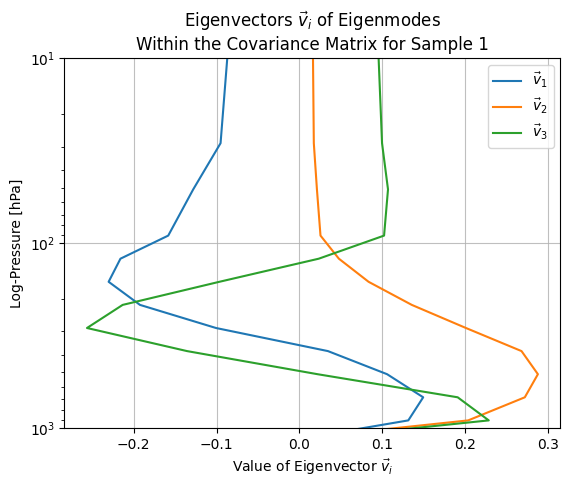

For Sample 1, the contribution of the first 3 modes is:
	99.638%


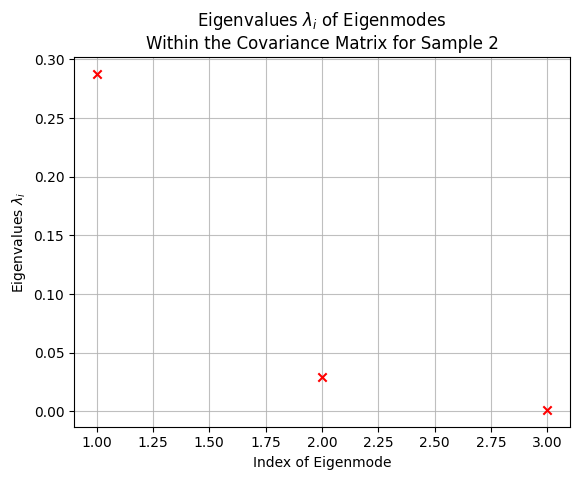

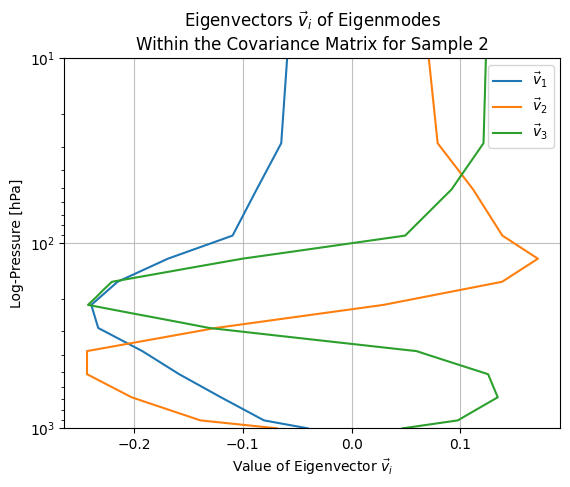

For Sample 2, the contribution of the first 3 modes is:
	99.974%


In [7]:
def make_eigenvalue_eigenvector_cov_plot(TES_cov, press_lev, sample_num):
    # calculate how many pieces of information are obtained in the retrievals
    evals, evecs = np.linalg.eig(TES_cov)

    sorting_indices = np.argsort(evals)[::-1]

    sorted_evals = evals[sorting_indices]
    sorted_evecs = evecs[:,sorting_indices]
    eval_indices = np.linspace(1,len(sorted_evals),len(sorted_evals))

    # make plot of eigenvalues to determine influential eigenmodes
    plt.scatter(eval_indices[:3], sorted_evals[:3], color='r', marker='x', zorder=2)
    plt.ylabel(r"Eigenvalues $\lambda_i$")
    plt.xlabel("Index of Eigenmode")
    plt.title(r"Eigenvalues $\lambda_i$ of Eigenmodes"+f"\nWithin the Covariance Matrix for Sample {sample_num}")
    plt.grid(alpha=0.8, zorder=1)
    plt.savefig(f"../plots/Q1c_{sample_num}_evals.png")
    plt.show()
    plt.close()

    # make plot of eigenvectors
    for i in range(3):
        plt.plot(sorted_evecs[:,i], press_lev, label=rf'$\vec{{v}}_{{{i+1}}}$')

    # add in grid and legend
    plt.legend()
    plt.grid(alpha=0.8)

    # add in titles and axis labels
    plt.title(rf"Eigenvectors $\vec{{v}}_{{i}}$ of Eigenmodes"+"\n"+rf"Within the Covariance Matrix for Sample {sample_num}")
    plt.ylabel("Log-Pressure [hPa]")
    plt.xlabel(r"Value of Eigenvector $\vec{{v}}_{{i}}$")

    # add scaling to yaxis
    plt.ylim(1000,10)
    plt.yscale("log")

    # show plot and close it
    plt.savefig(f"../plots/Q1c_{sample_num}_evecs.png")
    plt.show()
    plt.close()


    # calculate contribution of first 3 modes
    print(
            f"For Sample {sample_num}, the contribution of the first 3 modes is:\n"+
            f"\t{(sum(sorted_evals[:3])*100/sum(sorted_evals)):.5}%"
         )

    return


make_eigenvalue_eigenvector_cov_plot(TES_cov1, press_lev1, 1)
make_eigenvalue_eigenvector_cov_plot(TES_cov2, press_lev2, 2)



# Q1d

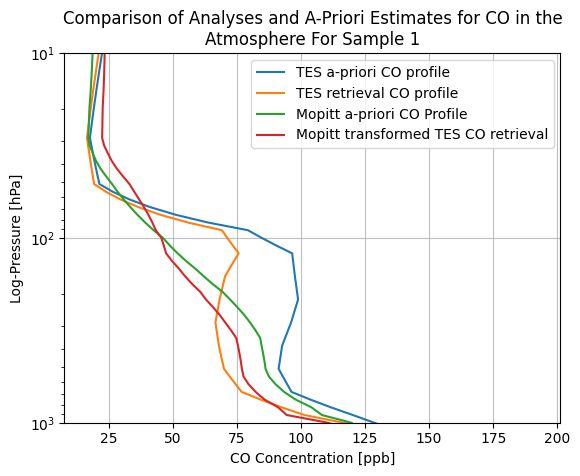

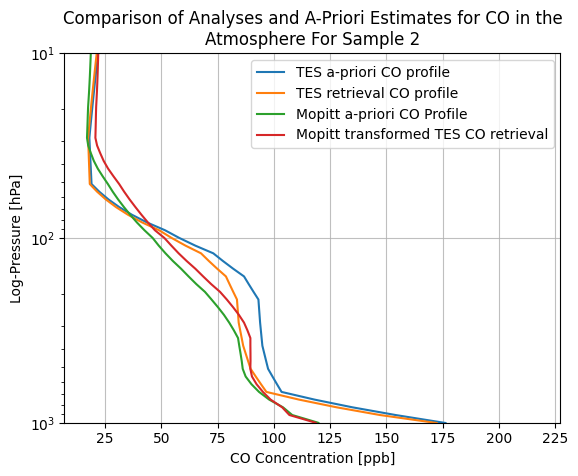

In [8]:
# press_lev1 = data1[:num_levs]
#         # Extract the second num_levs values for the a priori profile
# TES_prior1 = data1[num_levs:(num_levs+num_levs)]   
#         # Extract the last num_levs values for the retrieved profile
# TES_prof1 = data1[(num_levs+num_levs):]

def plot_analysis_for_singular_retrieval(TES_prior, TES_prof, press_lev,
                                         mopitt_prior, mopitt_prof, press_lev_mopitt,
                                         sample_num):
    plt.plot(TES_prior, press_lev, label="TES a-priori CO profile")
    plt.plot(TES_prof, press_lev, label="TES retrieval CO profile")
    plt.plot(mopitt_prior, press_lev_mopitt, label="Mopitt a-priori CO Profile")
    plt.plot(mopitt_prof, press_lev_mopitt, label="Mopitt transformed TES CO retrieval")


    # add labels to graph
    plt.ylabel("Log-Pressure [hPa]")
    plt.xlabel("CO Concentration [ppb]")
    plt.title(f"Comparison of Analyses and A-Priori Estimates for CO in the\nAtmosphere For Sample {sample_num}")

    # change y limits and scaling
    plt.ylim(1000,10)
    plt.yscale("log")

    # add legend and grid
    plt.legend()
    plt.grid(alpha=0.8)

    # show and close plot
    plt.savefig(f"../plots/Q1d_{sample_num}.png")
    plt.show()
    plt.close()


# perform analysis on MOPITT data
mopitt_prof1 = TES_prof1 - (np.eye(len(TES_prof1)) - TES_akern1)@TES_prior1 + (np.eye(len(TES_prof1)) - TES_akern1)@moppit_prior
mopitt_prof2 = TES_prof2 - (np.eye(len(TES_prof2)) - TES_akern2)@TES_prior2 + (np.eye(len(TES_prof2)) - TES_akern2)@moppit_prior



plot_analysis_for_singular_retrieval(TES_prior1, TES_prof1, press_lev1,
                                     moppit_prior, mopitt_prof1, press_levm,
                                     sample_num=1
                                    )

plot_analysis_for_singular_retrieval(TES_prior2, TES_prof2, press_lev2,
                                     moppit_prior, mopitt_prof2, press_levm,
                                     sample_num=2
                                    )